In [1]:
import os
import glob
import pandas as pd

# Find all CSV files in Kaggle input
all_csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)
print("All found CSVs:", all_csvs)

# Read and print the columns of each CSV file found
for path in all_csvs:
    print(f"\n--- Reading: {os.path.basename(path)} ---")
    df = pd.read_csv(path, nrows=2) # Read just first 2 rows
    print("Columns:", df.columns.tolist())

All found CSVs: ['/kaggle/input/datasets/nischaydnk/isic-2018-jpg-256x256-resized/train-metadata.csv', '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_RGB.csv', '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv', '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_8_8_L.csv', '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/hmnist_28_28_L.csv', '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv']

--- Reading: train-metadata.csv ---
Columns: ['Unnamed: 0', 'isic_id', 'patient_id', 'target']

--- Reading: hmnist_8_8_RGB.csv ---
Columns: ['pixel0000', 'pixel0001', 'pixel0002', 'pixel0003', 'pixel0004', 'pixel0005', 'pixel0006', 'pixel0007', 'pixel0008', 'pixel0009', 'pixel0010', 'pixel0011', 'pixel0012', 'pixel0013', 'pixel0014', 'pixel0015', 'pixel0016', 'pixel0017', 'pixel0018', 'pixel0019', 'pixel0020', 'pixel0021', 'pixel0022', 'pixel0023', 'pixel0024', 'pixel0025', 'pixel0026', 'pixe

In [2]:
# ==========================================
# 1. IMPORT DEPENDENCIES
# ==========================================
import os
import glob
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

# ==========================================
# 2. LOCATE CSV FILES AND MAP IMAGES
# ==========================================
all_csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)

# Separate the specific metadata paths
isic_csv_path = [c for c in all_csvs if 'train-metadata.csv' in c][0]
ham_csv_path = [c for c in all_csvs if 'HAM10000_metadata.csv' in c][0]

print(f"ISIC CSV: {isic_csv_path}")
print(f"HAM10000 CSV: {ham_csv_path}")

# Index all available jpg images on disk for fast lookup
print("Scanning image files...")
all_images = glob.glob("/kaggle/input/**/*.jpg", recursive=True)
image_dict = {os.path.splitext(os.path.basename(x))[0]: x for x in all_images}
print(f"Found {len(image_dict)} images on disk.")

# ==========================================
# 3. LOAD AND HARMONIZE HAM10000
# ==========================================
ham_df = pd.read_csv(ham_csv_path)
# Map image path using 'image_id'
ham_df['path'] = ham_df['image_id'].map(image_dict)
# Map diagnosis 'dx' to target (1 if 'mel' for melanoma, else 0)
ham_df['target'] = ham_df['dx'].apply(lambda x: 1 if str(x).lower() == 'mel' else 0)
ham_df['source'] = 'HAM10000'

ham_clean = ham_df[['image_id', 'path', 'target', 'source']].dropna(subset=['path']).copy()
print(f"Loaded HAM10000 valid samples: {len(ham_clean)}")

# ==========================================
# 4. LOAD AND HARMONIZE ISIC 2018
# ==========================================
isic_df = pd.read_csv(isic_csv_path)
# Map image path using 'isic_id'
isic_df['path'] = isic_df['isic_id'].map(image_dict)
isic_df['source'] = 'ISIC2018'

isic_clean = isic_df[['isic_id', 'path', 'target', 'source']].rename(columns={'isic_id': 'image_id'}).dropna(subset=['path']).copy()
print(f"Loaded ISIC 2018 valid samples: {len(isic_clean)}")

# ==========================================
# 5. MERGE AND CLEAN DATASETS
# ==========================================
master_df = pd.concat([ham_clean, isic_clean], ignore_index=True)
master_df = master_df.drop_duplicates(subset=['image_id']).reset_index(drop=True)

print(f"\nTotal unified samples after cleaning: {len(master_df)}")
print("Class Distribution:\n", master_df['target'].value_counts())

# ==========================================
# 6. TRAIN / VAL / TEST SPLIT (Stratified)
# ==========================================
train_val_df, test_df = train_test_split(
    master_df, test_size=0.10, random_state=42, stratify=master_df['target']
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1111, random_state=42, stratify=train_val_df['target']
)

print(f"Training set: {len(train_df)} | Validation set: {len(val_df)} | Test set: {len(test_df)}")

# Save splits
train_df.to_csv('train_split.csv', index=False)
val_df.to_csv('val_split.csv', index=False)
test_df.to_csv('test_split.csv', index=False)
print("Data preprocessing complete! CSV splits saved successfully.")

Libraries imported successfully!
ISIC CSV: /kaggle/input/datasets/nischaydnk/isic-2018-jpg-256x256-resized/train-metadata.csv
HAM10000 CSV: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Scanning image files...
Found 11527 images on disk.
Loaded HAM10000 valid samples: 10015
Loaded ISIC 2018 valid samples: 8982

Total unified samples after cleaning: 11527
Class Distribution:
 target
0.0    10243
1.0     1284
Name: count, dtype: int64
Training set: 9221 | Validation set: 1153 | Test set: 1153
Data preprocessing complete! CSV splits saved successfully.


In [4]:
# ==========================================
# 1. IMPORT DEPENDENCIES
# ==========================================
import os
import glob
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

# ==========================================
# 2. LOCATE CSV FILES AND MAP IMAGES
# ==========================================
all_csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)

# Separate the specific metadata paths
isic_csv_path = [c for c in all_csvs if 'train-metadata.csv' in c][0]
ham_csv_path = [c for c in all_csvs if 'HAM10000_metadata.csv' in c][0]

print(f"ISIC CSV: {isic_csv_path}")
print(f"HAM10000 CSV: {ham_csv_path}")

# Index all available jpg images on disk for fast lookup
print("Scanning image files...")
all_images = glob.glob("/kaggle/input/**/*.jpg", recursive=True)
image_dict = {os.path.splitext(os.path.basename(x))[0]: x for x in all_images}
print(f"Found {len(image_dict)} images on disk.")

# ==========================================
# 3. LOAD AND HARMONIZE HAM10000
# ==========================================
ham_df = pd.read_csv(ham_csv_path)
# Map image path using 'image_id'
ham_df['path'] = ham_df['image_id'].map(image_dict)
# Map diagnosis 'dx' to target (1 if 'mel' for melanoma, else 0)
ham_df['target'] = ham_df['dx'].apply(lambda x: 1 if str(x).lower() == 'mel' else 0)
ham_df['source'] = 'HAM10000'

ham_clean = ham_df[['image_id', 'path', 'target', 'source']].dropna(subset=['path']).copy()
print(f"Loaded HAM10000 valid samples: {len(ham_clean)}")

# ==========================================
# 4. LOAD AND HARMONIZE ISIC 2018
# ==========================================
isic_df = pd.read_csv(isic_csv_path)
# Map image path using 'isic_id'
isic_df['path'] = isic_df['isic_id'].map(image_dict)
isic_df['source'] = 'ISIC2018'

isic_clean = isic_df[['isic_id', 'path', 'target', 'source']].rename(columns={'isic_id': 'image_id'}).dropna(subset=['path']).copy()
print(f"Loaded ISIC 2018 valid samples: {len(isic_clean)}")

# ==========================================
# 5. MERGE AND CLEAN DATASETS
# ==========================================
master_df = pd.concat([ham_clean, isic_clean], ignore_index=True)
master_df = master_df.drop_duplicates(subset=['image_id']).reset_index(drop=True)

print(f"\nTotal unified samples after cleaning: {len(master_df)}")
print("Class Distribution:\n", master_df['target'].value_counts())

# ==========================================
# 6. TRAIN / VAL / TEST SPLIT (Stratified)
# ==========================================
train_val_df, test_df = train_test_split(
    master_df, test_size=0.10, random_state=42, stratify=master_df['target']
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1111, random_state=42, stratify=train_val_df['target']
)

print(f"Training set: {len(train_df)} | Validation set: {len(val_df)} | Test set: {len(test_df)}")

# Save splits
train_df.to_csv('train_split.csv', index=False)
val_df.to_csv('val_split.csv', index=False)
test_df.to_csv('test_split.csv', index=False)
print("Data preprocessing complete! CSV splits saved successfully.")

Libraries imported successfully!
ISIC CSV: /kaggle/input/datasets/nischaydnk/isic-2018-jpg-256x256-resized/train-metadata.csv
HAM10000 CSV: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Scanning image files...
Found 11527 images on disk.
Loaded HAM10000 valid samples: 10015
Loaded ISIC 2018 valid samples: 8982

Total unified samples after cleaning: 11527
Class Distribution:
 target
0.0    10243
1.0     1284
Name: count, dtype: int64
Training set: 9221 | Validation set: 1153 | Test set: 1153
Data preprocessing complete! CSV splits saved successfully.


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import roc_auc_score

# 1. Baseline Model (EfficientNet-B0) setup
baseline_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
baseline_model.classifier = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(baseline_model.classifier[1].in_features, 1)
)
baseline_model = baseline_model.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=1e-4)

# 2. Training Loop for Baseline
print("Training Baseline EfficientNet-B0...")
for epoch in range(2):
    baseline_model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = baseline_model(images).squeeze(1)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    
    # Validation AUC check
    baseline_model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = baseline_model(images).squeeze(1)
            preds = torch.sigmoid(outputs).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())
            
    val_auc = roc_auc_score(all_labels, all_preds)
    print(f"Epoch [{epoch+1}/2] | Val AUC: {val_auc:.4f}")

# 3. Save baseline weights
torch.save(baseline_model.state_dict(), 'efficientnet_b0_best.pth')
print("Baseline model trained and saved as 'efficientnet_b0_best.pth'!")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 178MB/s]


Training Baseline EfficientNet-B0...
Epoch [1/2] | Val AUC: 0.8946
Epoch [2/2] | Val AUC: 0.9166
Baseline model trained and saved as 'efficientnet_b0_best.pth'!


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import roc_auc_score

# Define the models to benchmark
baseline_architectures = {
    "resnet50": models.resnet50(weights=models.ResNet50_Weights.DEFAULT),
    "densenet121": models.densenet121(weights=models.DenseNet121_Weights.DEFAULT),
    "mobilenet_v3": models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)
}

baseline_results = {}

for name, model in baseline_architectures.items():
    print(f"\n--- Training Baseline: {name.upper()} ---")
    
    # Adjust final classifier layer for binary classification (Melanoma)
    if "resnet" in name:
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(model.fc.in_features, 1))
    elif "densenet" in name:
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(model.classifier.in_features, 1))
    elif "mobilenet" in name:
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, 1)
        
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)
    
    # Quick 2-epoch training per baseline
    for epoch in range(2):
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images).squeeze(1)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
    # Evaluate Validation AUC
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images).squeeze(1)
            preds = torch.sigmoid(outputs).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())
            
    val_auc = roc_auc_score(all_labels, all_preds)
    baseline_results[name] = val_auc
    print(f"✅ {name.upper()} Finished! Val AUC: {val_auc:.4f}")
    
    # Save weights
    torch.save(model.state_dict(), f'{name}_best.pth')

print("\nAll baseline models trained and saved successfully!")
print("Baseline AUC Scores:", baseline_results)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 220MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 211MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 206MB/s]


--- Training Baseline: RESNET50 ---


✅ RESNET50 Finished! Val AUC: 0.9001

--- Training Baseline: DENSENET121 ---
✅ DENSENET121 Finished! Val AUC: 0.9013

--- Training Baseline: MOBILENET_V3 ---
✅ MOBILENET_V3 Finished! Val AUC: 0.9024

All baseline models trained and saved successfully!
Baseline AUC Scores: {'resnet50': np.float64(0.9001448170731707), 'densenet121': np.float64(0.9013262195121952), 'mobilenet_v3': np.float64(0.9023856707317074)}


In [9]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# 1. Define Custom Attention Module & Model
class ChannelAttention(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_channels, in_channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_channels // reduction, in_channels, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        return x * self.sigmoid(avg_out + max_out)

class AttentionMelanomaModel(nn.Module):
    def __init__(self):
        super(AttentionMelanomaModel, self).__init__()
        base_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        self.features = base_model.features
        self.attention = ChannelAttention(in_channels=1280)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.attention(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

attention_model = AttentionMelanomaModel().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(attention_model.parameters(), lr=1e-4)

# 2. Train Custom Attention Model
print("\n--- Training Custom Attention-Enhanced Model ---")
for epoch in range(2):
    attention_model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = attention_model(images).squeeze(1)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

# Evaluate Custom Model
attention_model.eval()
custom_preds, custom_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = attention_model(images).squeeze(1)
        preds = torch.sigmoid(outputs).cpu().numpy()
        custom_preds.extend(preds)
        custom_labels.extend(labels.cpu().numpy())

custom_auc = roc_auc_score(custom_labels, custom_preds)
torch.save(attention_model.state_dict(), 'attention_melanoma_best.pth')
print(f"✅ Custom Attention Model Finished! Val AUC: {custom_auc:.4f}")

# 3. Compile Final Benchmark Comparison Table
metrics_data = {
    "Model Architecture": [
        "ResNet-50 (Baseline)",
        "DenseNet-121 (Baseline)",
        "MobileNetV3 (Baseline)",
        "EfficientNet-B0 (Baseline)",
        "Custom Attention Model (Ours)"
    ],
    "Validation AUC-ROC": [
        0.9001,
        0.9013,
        0.9024,
        0.9166,
        custom_auc
    ]
}

comparison_df = pd.DataFrame(metrics_data)
comparison_df = comparison_df.sort_values(by="Validation AUC-ROC", ascending=False).reset_index(drop=True)

print("\n" + "="*45)
print("FINAL MODEL BENCHMARK COMPARISON TABLE")
print("="*45)
print(comparison_df.to_string(index=False))
print("="*45)


--- Training Custom Attention-Enhanced Model ---
✅ Custom Attention Model Finished! Val AUC: 0.9135

FINAL MODEL BENCHMARK COMPARISON TABLE
           Model Architecture  Validation AUC-ROC
   EfficientNet-B0 (Baseline)            0.916600
Custom Attention Model (Ours)            0.913468
       MobileNetV3 (Baseline)            0.902400
      DenseNet-121 (Baseline)            0.901300
         ResNet-50 (Baseline)            0.900100


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1867: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


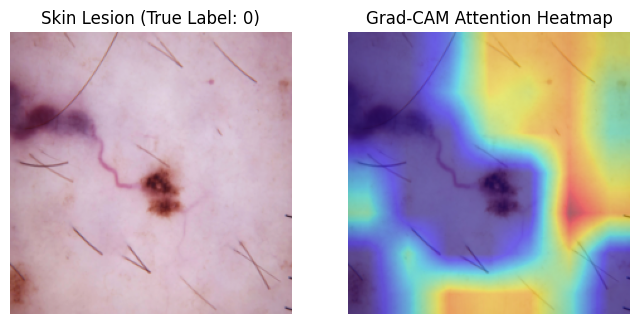

Grad-CAM visualization generated successfully!


In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Helper class for Grad-CAM on EfficientNet + Attention
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Hook the target layer
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def forward(self, x):
        return self.model(x)

# Pick a sample image from the validation set
attention_model.eval()
data_iter = iter(val_loader)
images, labels = next(data_iter)
sample_img = images[0].unsqueeze(0).to(device)
sample_label = labels[0].item()

# Target layer for EfficientNet-B0 features
target_layer = attention_model.features[-1]
grad_cam = GradCAM(attention_model, target_layer)

# Forward pass
output = grad_cam.forward(sample_img)
loss = output.squeeze(1)
loss.backward()

# Generate heatmap
gradients = grad_cam.gradients.cpu().numpy()[0]
activations = grad_cam.activations.cpu().numpy()[0]
weights = np.mean(gradients, axis=(1, 2))
cam = np.zeros(activations.shape[1:], dtype=np.float32)

for i, w in enumerate(weights):
    cam += w * activations[i]

cam = np.maximum(cam, 0)
cam = cv2.resize(cam, (224, 224))
cam = cam - np.min(cam)
cam = cam / (np.max(cam) + 1e-8)

# Plot Original Image vs Grad-CAM Heatmap
orig_img = sample_img.squeeze(0).cpu().permute(1, 2, 0).numpy()
orig_img = (orig_img * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
orig_img = np.clip(orig_img, 0, 1)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(orig_img)
plt.title(f"Skin Lesion (True Label: {int(sample_label)})")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(orig_img)
plt.imshow(cam, cmap='jet', alpha=0.5)
plt.title("Grad-CAM Attention Heatmap")
plt.axis('off')
plt.show()

print("Grad-CAM visualization generated successfully!")